<a href="https://colab.research.google.com/github/majax23/Uczenie-glebokie-do-rozpoznawania-obiektow-MS/blob/main/LAB1_Zadanie_Maja_S%CC%81winiarska.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import bibliotek i wybór urządzenia**

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


# **Przygotowanie danych**

Do klasycznego perceptronu wielowarstwowego (MLP) najlepiej nadaje się FashionMNIST. Sieci gęste (MLP) wymagają spłaszczenia obrazu do jednowymiarowego wektora.

Dla FashionMNIST (28x28, 1 kanał) daje to wektor o rozmiarze 784.
Gdybyśmy wybrali CIFAR-10 (32x32, 3 kanały), wektor wejściowy miałby rozmiar 3072, co w pełni połączonych warstwach drastycznie zwiększyłoby liczbę parametrów, wydłużyło czas treningu i znacznie zwiększyło ryzyko przeuczenia.

In [2]:
mean, std = 0.2860, 0.3530  #statystyki FashionMNIST
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 179kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.25MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.4MB/s]

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000


# **MLP**
Badanie wpływu architektury

In [3]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10):
        super().__init__()
        layers = [nn.Flatten()]
        current_dim = in_dim
        for h in hidden:
            layers.append(nn.Linear(current_dim, h))
            layers.append(nn.ReLU())
            current_dim = h
        layers.append(nn.Linear(current_dim, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# **Ewaluacja**

In [4]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

# **Trening**

In [5]:
def train_model(hidden_layers, epochs=8, lr=0.001):
    model = MLP(hidden=hidden_layers).to(device)
    n_params = sum(p.numel() for p in model.parameters()) #liczba parametrów dla danego wariantu
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    for epoch in range(1, epochs+1):
        model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item()*yb.numel()

        train_loss = run_loss/len(train_ds)
        test_loss, test_acc = evaluate(model, test_dl)

        hist["train_loss"].append(train_loss)
        hist["test_loss"].append(test_loss)
        hist["test_acc"].append(test_acc)

    return model, n_params, hist

# **Badanie wariantów architektury**
Przetestowanie co najmniej trzech wariantów różniących się warstwami.

In [6]:
variants = [(128,), (256, 128), (512, 256, 128)]
results = []

best_acc = 0
best_model = None
best_hist = None
best_variant = None

print(f"{'Architektura':<20} | {'Parametry':<10} | {'Accuracy (Test)':<15}")
print("-" * 50)

for hidden in variants:
    model, n_params, hist = train_model(hidden_layers=hidden, epochs=8)
    final_acc = hist["test_acc"][-1] * 100
    print(f"{str(hidden):<20} | {n_params:<10} | {final_acc:.2f}%") #tabela z wynikami

    if final_acc > best_acc: #zapisanie najlepszego modelu
        best_acc = final_acc
        best_model = model
        best_hist = hist
        best_variant = hidden

Architektura         | Parametry  | Accuracy (Test)
--------------------------------------------------
(128,)               | 101770     | 88.18%
(256, 128)           | 235146     | 88.02%
(512, 256, 128)      | 567434     | 88.43%


# **Krzywe uczenia dla najlepszego modelu**


Najlepszy wariant to (512, 256, 128) z wynikiem 88.43%


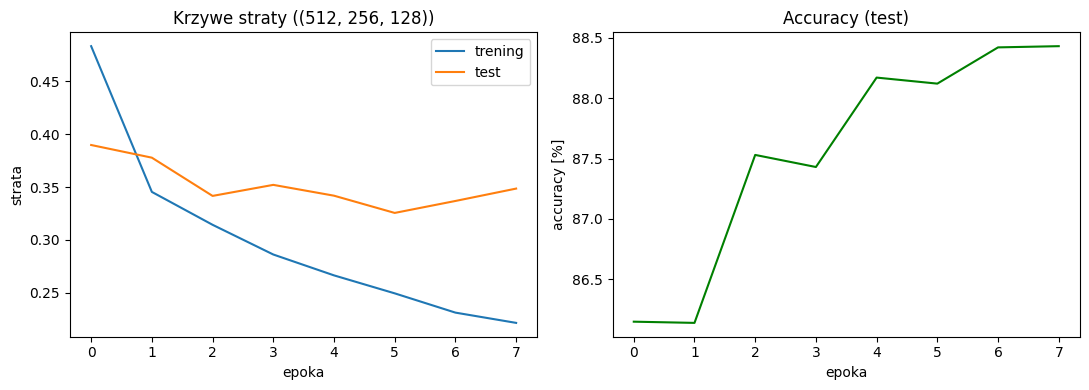

In [7]:
print(f"\nNajlepszy wariant to {best_variant} z wynikiem {best_acc:.2f}%")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(best_hist["train_loss"], label="trening")
ax1.plot(best_hist["test_loss"], label="test")
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata"); ax1.legend(); ax1.set_title(f"Krzywe straty ({best_variant})")
ax2.plot([a*100 for a in best_hist["test_acc"]], color="green")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.set_title("Accuracy (test)")
plt.tight_layout(); plt.show()

#**Siatka predykcji**

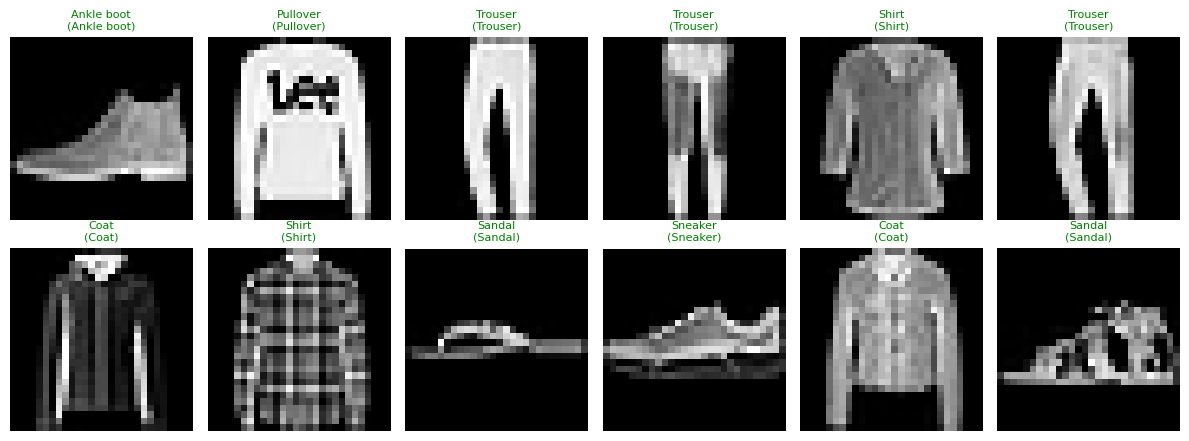

In [8]:
best_model.eval()
xb, yb = next(iter(test_dl))
with torch.no_grad():
    pred = best_model(xb.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.flat, range(12)):
    ax.imshow(xb[i].squeeze()*std + mean, cmap="gray")
    ok = pred[i].item() == yb[i].item()
    ax.set_title(f"{classes[pred[i]]}\n({classes[yb[i]]})", fontsize=8, color="green" if ok else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

# ***Macierz pomyłek i analiza klas**

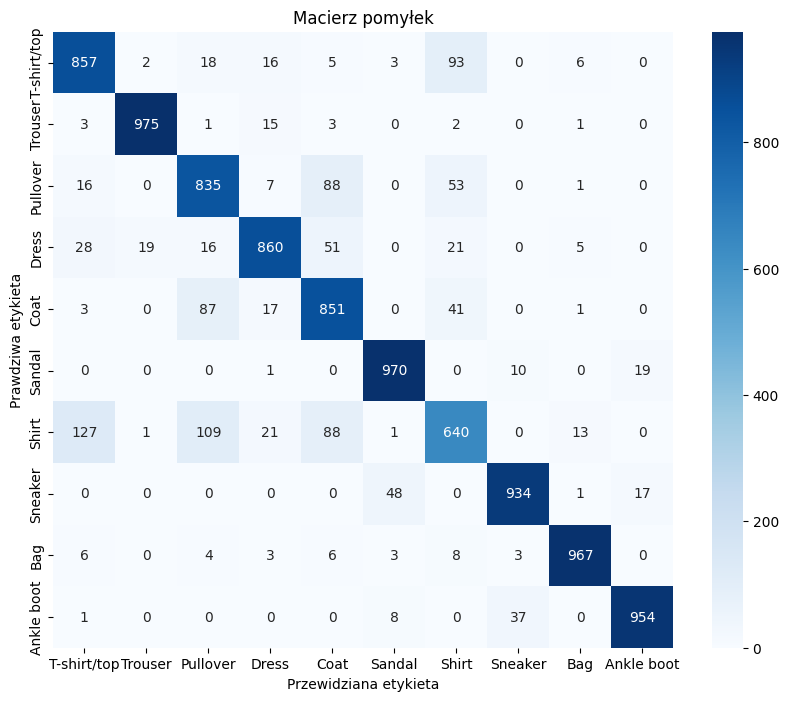

In [9]:
all_preds = []
all_labels = []
with torch.no_grad():
    for xb, yb in test_dl:
        out = best_model(xb.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(yb.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Macierz pomyłek")
plt.ylabel("Prawdziwa etykieta")
plt.xlabel("Przewidziana etykieta")
plt.show()

# ***Badanie wpływu współczynnika uczenia**


Badanie wpływu współczynnika uczenia (LR) dla wariantu (512, 256, 128):
Learning Rate   | Accuracy (Test)
-----------------------------------
0.01            | 85.77%
0.001           | 88.62%
0.0001          | 87.14%


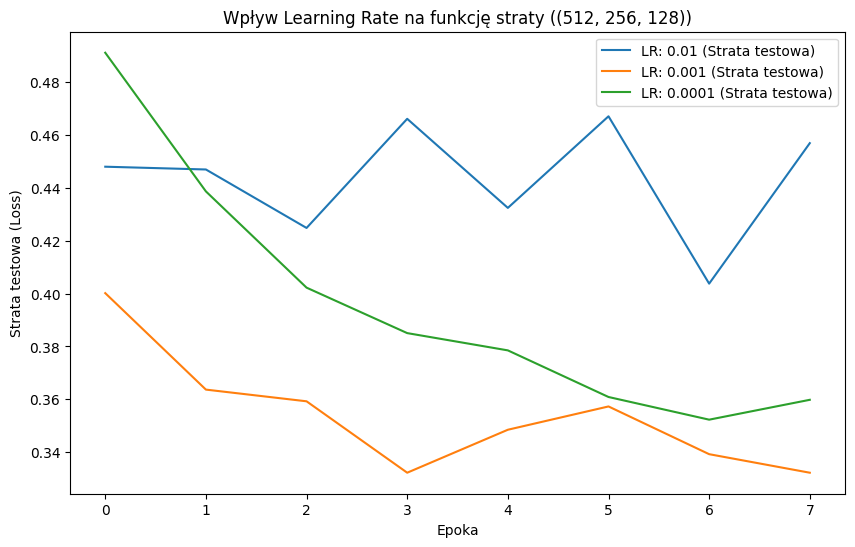

In [10]:
learning_rates = [0.01, 0.001, 0.0001]
plt.figure(figsize=(10, 6))

print(f"\nBadanie wpływu współczynnika uczenia (LR) dla wariantu {best_variant}:")
print(f"{'Learning Rate':<15} | {'Accuracy (Test)':<15}")
print("-" * 35)

for lr in learning_rates:
    _, _, hist = train_model(hidden_layers=best_variant, epochs=8, lr=lr)
    final_acc = hist["test_acc"][-1] * 100
    print(f"{lr:<15} | {final_acc:.2f}%")
    plt.plot(hist["test_loss"], label=f'LR: {lr} (Strata testowa)')

plt.title(f"Wpływ Learning Rate na funkcję straty ({best_variant})")
plt.xlabel("Epoka")
plt.ylabel("Strata testowa (Loss)")
plt.legend()
plt.show()